# Lab 7

Author: Khanh Do

In [2]:
# Imports
import warnings   # Turns off the future warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import xgboost as xgb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

In [3]:
# Data
# Well switching data
wells = pd.read_csv("https://remiller1450.github.io/data/Wells.csv")

# Train-test split
from sklearn.model_selection import train_test_split
train, test = train_test_split(wells, test_size=0.1, random_state=9)

# Separate the outcome and predictors (and drop the "association" predictor)
train_y = (train['switch'] == 'yes').astype(int)
train_X = train.drop(['switch', 'association'], axis="columns")
test_y = (test['switch'] == 'yes').astype(int)
test_X = test.drop(['switch', 'association'], axis="columns")

Standard practice is to first find a configuration for the base learners that works adequately well, then to find a learning rate that is not too aggressive or too slow, then use early stopping to determine the effective number of boosting iterations.

## Question 1

We are only tuning the structure of the base learners in this section, we will keep the ensemble-level parameters fixed at their defaults. 

### Part A

In [4]:
## Simple pipeline
from sklearn.model_selection import RandomizedSearchCV
import xgboost as xgb

## Simple xgboost model
model1 = xgb.XGBClassifier(eval_metric='auc')

## Randomized search space
parms = {
    "max_depth": [2, 3, 4, 5, 6],
    "min_child_weight": [1, 5, 10, 20],
    "subsample": [0.50, 0.75, 1.00],
    "colsample_bytree": [0.50, 0.75, 1.00]
}

## Randomized search
rand_res = RandomizedSearchCV(model1, param_distributions=parms, n_iter=20, scoring="roc_auc", cv=5, n_jobs=-1).fit(train_X, train_y)
params_to_print = [
    'param_max_depth',
    'param_min_child_weight',
    'param_subsample',
    'param_colsample_bytree',
    'mean_test_score'
]

pd.DataFrame(rand_res.cv_results_).sort_values(by='mean_test_score', ascending=True)[params_to_print]

,param_max_depth,param_min_child_weight,param_subsample,param_colsample_bytree,mean_test_score
19,6,1,0.75,0.75,0.597845
17,6,5,0.50,1.00,0.601487
0,6,1,1.00,0.50,0.608233
8,4,1,1.00,1.00,0.613959
16,5,5,1.00,0.75,0.616223
4,5,1,1.00,0.75,0.618492
12,3,1,0.75,1.00,0.619724
3,4,1,1.00,0.75,0.620956
15,3,5,0.75,1.00,0.625172
11,6,20,0.50,0.75,0.628296


**Comment:** There are some patterns in the lower performed models:
- For `max_depth`, depths higher than 4 seems to be associated with lower auc score, though not strictly.
- For `min_child_weight`, there are more 1s and 5s for the lower auc score models.
- For `subsample`, it is not too clear so best not to remove any.
- For `colsample_bytree`, it seems like 0.75 appears more on the lower auc score models than 1.00 and 0.50. 

In [5]:
## Updated randomized search space
parms_updated = {
    "max_depth": [2, 3, 4],
    "min_child_weight": [10, 20],
    "subsample": [0.50, 0.75, 1.00],
    "colsample_bytree": [0.50, 1.00],
    "reg_alpha": [0, 10],
    "reg_lambda": [0, 10]
}

## Randomized search
rand_res_updated = RandomizedSearchCV(model1, param_distributions=parms_updated, n_iter=30, scoring="roc_auc", cv=5, n_jobs=-1).fit(train_X, train_y)
print(rand_res_updated.best_estimator_)
print(rand_res_updated.best_score_)
print(rand_res_updated.best_params_)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=1.0, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='auc', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=20, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)
0.659851454616474
{'subsample': 1.0, 'reg_lambda': 10, 'reg_alpha': 10, 'min_child_weight': 20, 'max_depth': 3, 'colsample_bytree': 1.0}


### Part B

In [6]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
# cross-validated score of a single decision tree with max depth of 12
auc_score = cross_val_score(
    DecisionTreeClassifier(max_depth=12),
    train_X,
    train_y,
    scoring="roc_auc",
    cv=5
).mean()
print(rand_res_updated.best_score_)
print(auc_score)

0.659851454616474
0.5847622620837107


**Comment:** The Boosted model performed better than the single decision tree with depth of 12. The reason for this is that the single decision tree has a depth too high that and may overfit the training data. Also, XGBoost combines multiple shallow trees, helps retain the helpful information every iteration and try to correct the pattern that we didn't get last iteration.

## Question 2

### Part A

The higher the `learning_rate`, the more a new model in a boosting iteration contributes, so the more the overall model changes. When the `learning_rate` is small, the model changes less, which can produce a more gradual AUC but usually requires more trees because this gradual change is slower. Therefore, a small `learning_rate` needs a larger `early_stopping_round` to give these small updates enough time to produce a noticeable improvement/optimize in AUC before stopping.

### Part B

In [7]:
## Create validation set
xgb_train_X, val_X, xgb_train_y, val_y = train_test_split(train_X,train_y,test_size=0.25,random_state=0)

learning_rates = [0.01, 0.1, 0.3]
base_model = rand_res_updated.best_estimator_
saved_results = []

from sklearn.base import clone
for learning_rate in learning_rates:
    curr_model = clone(base_model)
    curr_model.set_params(early_stopping_rounds=40, learning_rate=learning_rate, n_estimators=5000, eval_metric="auc")
    curr_model.fit(xgb_train_X, xgb_train_y, eval_set=[(xgb_train_X, xgb_train_y),(val_X, val_y)],verbose=False)
    print(f"learning rate = {learning_rate}")
    print("best iter =", curr_model.best_iteration)
    print("best score =",curr_model.best_score)
    print("--------")
    auc_history = curr_model.evals_result()["validation_1"]["auc"]
    saved_results.append(auc_history)



learning rate = 0.01
best iter = 60
best score = 0.6454392208278704
--------
learning rate = 0.1
best iter = 18
best score = 0.6467191109446213
--------
learning rate = 0.3
best iter = 28
best score = 0.6479722437767016
--------


**Comment:** The largest learning rate of 0.3 seems to performed the best but the difference in auc between the three is very minimal.

### Part C

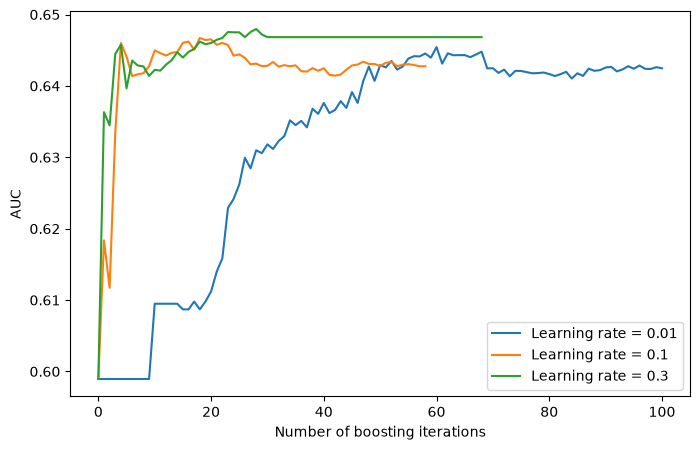

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(saved_results[0], label="Learning rate = 0.01")
plt.plot(saved_results[1], label="Learning rate = 0.1")
plt.plot(saved_results[2], label="Learning rate = 0.3")
plt.xlabel("Number of boosting iterations")
plt.ylabel("AUC")
plt.legend()
plt.show()

**Comment:** the higher the learning rate, the more agressive the model behaved but also a lot of jumps/strikes because the model changes more. Very apparent is that the small learning rate, 0.01, curve has a more gradual increase in AUC and smoother curve.

## Question 3

### Part A

We should calculate the Loss at p = 0.8 and Loss at p = 0.7 then find the difference.

In [9]:
import math
positive_class = 1
loss08 = -(positive_class*math.log(0.8) + (1 - positive_class)*math.log(1-0.8))
loss07 = -(positive_class*math.log(0.7) + (1 - positive_class)*math.log(1-0.7))
print(f"The contribution to the log-loss changes is {loss08 - loss07}")

The contribution to the log-loss changes is -0.13353139262452274


### Part B

To improve the AUC, we need to enhance the model's ability to rank positive observations higher than negative observations. Thus, the positive observation must improve its ranking relative to at least one negative observation. In the scenario described in Part A, there must be another negative observation (call it A) with probability between 0.7 - 0.8, then when the probability of one positive observation (call it B) increases from 0.7 to 0.8, now B outranks A, thus improves the AUC.

### Part C

A practitioner might prefer log-loss because, unlike AUC where there has to be a difference in ordering of observations ranking to see a change, it rewards models for producing probabilities that are both correct and confident, penalize confident mistakes, and is sensitive to small improvements in predicted probabilities. Thus, it might be preferred when monitoring early stopping even when AUC is the final metric.

### Part D

I would recommend a lower `early_stopping_rounds` because we are using log-loss and log-loss is sensitive to changes in predicted probabilities. However, for AUC I would use a higher `early_stopping_rounds` because like we have said, there has to be a change in ordering of rankings for the AUC to change, which means it might need to run for more iterations before that change is reflected.

## Question 4

In [10]:
## Read the data
wbc = pd.read_csv("https://remiller1450.github.io/data/wisc_bc.csv")

In [11]:
wbc.shape

(569, 12)

### Part A

In [ ]:
# Separate label and predictors
wbc_y = wbc['Label']
wbc_X = wbc.drop(columns=['ID', 'Label'])

# Turn B, M label into 0, 1
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
wbc_y_encoded = le.fit_transform(wbc_y)

# Split data into a training set consisting of 80% of the observations and a test set consisting of the remaining 20%
wbc_train_X, wbc_test_X, wbc_train_y, wbc_test_y = train_test_split(wbc_X, wbc_y_encoded, test_size=0.2, random_state=9)

# Split the training set once more so that 25% of it is used for validation
wbc_train_X, wbc_val_X, wbc_train_y, wbc_val_y = train_test_split(wbc_train_X, wbc_train_y, test_size=0.25, random_state=9)

### Part B

In [13]:
## Simple xgboost model
model4b = xgb.XGBClassifier(eval_metric='auc', random_state=9)

## Randomized search space
parms4b = {
    "max_depth": [2, 3, 4],
    "min_child_weight": [5, 10, 20],
    "subsample": [0.50, 0.75, 1.00],
    "colsample_bytree": [0.50, 0.75, 1.00],
    "reg_alpha": [0, 1, 10],
    "reg_lambda": [0, 1, 10]
}

## Randomized search
rand_res_4b = RandomizedSearchCV(model4b, param_distributions=parms4b, n_iter=30, scoring="roc_auc", cv=5, n_jobs=-1, random_state=9).fit(wbc_train_X, wbc_train_y)
print(rand_res_4b.best_estimator_)
print(rand_res_4b.best_score_)
print(rand_res_4b.best_params_)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.5, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='auc', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=5, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)
0.9845330948121646
{'subsample': 0.5, 'reg_lambda': 10, 'reg_alpha': 0, 'min_child_weight': 5, 'max_depth': 3, 'colsample_bytree': 0.5}


### Part C

In [14]:
learning_rates = [0.01, 0.1, 0.3]
base_model = rand_res_4b.best_estimator_
saved_results = []
saved_models = []

for learning_rate in learning_rates:
    curr_model = clone(base_model)
    curr_model.set_params(early_stopping_rounds=40, learning_rate=learning_rate, n_estimators=5000, eval_metric="logloss")
    curr_model.fit(wbc_train_X, wbc_train_y, eval_set=[(wbc_train_X, wbc_train_y),(wbc_val_X, wbc_val_y)],verbose=False)
    print(f"learning rate = {learning_rate}")
    print("best iter =", curr_model.best_iteration)
    print("best validation log-loss =", curr_model.evals_result()["validation_1"]["logloss"][curr_model.best_iteration])
    print("--------")
    saved_models.append(curr_model)  # this is for 4D
    logloss_history = (curr_model.evals_result()["validation_0"]["logloss"], curr_model.evals_result()["validation_1"]["logloss"])
    saved_results.append(logloss_history)  # this is for easy graphing

learning rate = 0.01
best iter = 1043
best validation log-loss = 0.22598557134992198
--------
learning rate = 0.1
best iter = 146
best validation log-loss = 0.22647913074807116
--------
learning rate = 0.3
best iter = 54
best validation log-loss = 0.22958769001426144
--------


**Comment:** Since we're using log-loss, the best score is the lowest one, which is from the model with learning rate of 0.01, best iteration at 1043.

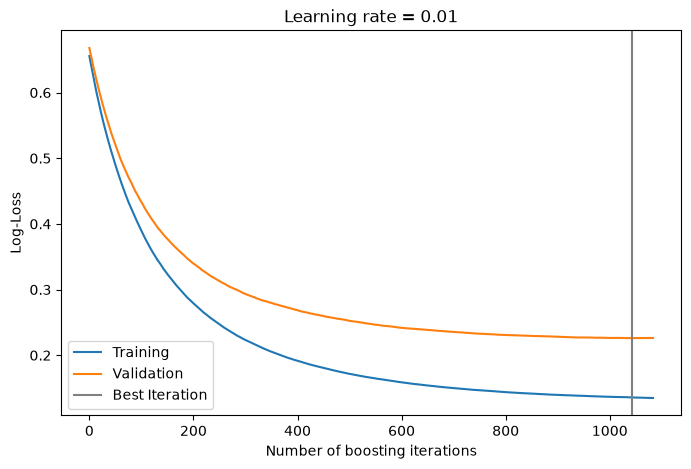

In [15]:
plt.figure(figsize=(8, 5))
plt.plot(saved_results[0][0], label="Training")
plt.plot(saved_results[0][1], label="Validation")
plt.axvline(1043, color="gray", label="Best Iteration")

plt.xlabel("Number of boosting iterations")
plt.ylabel("Log-Loss")
plt.title("Learning rate = 0.01")
plt.legend()
plt.show()

**Comment:** I selected `learning_rate=0.01` because it achieved the lowest validation log-loss among the rates tested. I also tried adding learning rates of 0.005, 0.05 and 0.2 to the test and early stopping round values of 50, 60, and 80. The learning rate of 0.01 remained the strongest choice throughout. I didn't choose a very small early stopping rounds because I want to give low learning rate like 0.01 a chance to improve after temporal plateu. After some testing, looking at learning rate of 0.01, early stopping rounds of 40 and 50 both selected best iteration 1043, while 60 and 80 gave only slightly lower validation log-loss with additional computation and higher best iteration. Thus, I kept `early_stopping_rounds=40` as a reasonable balance between performance and computational cost.

### Part D

In [16]:
from sklearn.metrics import accuracy_score, roc_auc_score

# Our best model is the first saved one with learning rate = 0.01
best_model4c = saved_models[0]

# Use the model to predict on test set
test_pred4d = best_model4c.predict(wbc_test_X)

# Use predict probability for roc-auc
test_prob4d = best_model4c.predict_proba(wbc_test_X)[:, 1]

# Calc the scores
accuracy4d = accuracy_score(wbc_test_y, test_pred4d)
auc4d = roc_auc_score(wbc_test_y, test_prob4d)

print('classification accuracy =', accuracy4d)
print('ROC-AUC =', auc4d)

classification accuracy = 0.9122807017543859
ROC-AUC = 0.9864864864864864


### Part E

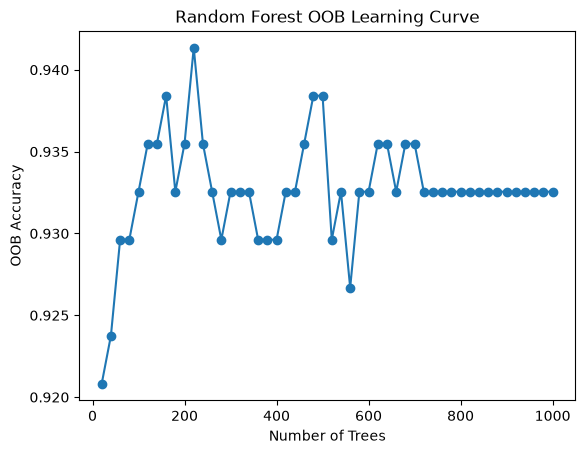

In [ ]:
# Find n_estimators
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(oob_score=True, random_state=9)

n_trees = []
oob_acc = []

## Increment the number of base learners, tracking OOB accuracy 
for n in range(20, 1001, 20):
    rf.n_estimators = n
    rf.fit(wbc_train_X, wbc_train_y)

    n_trees.append(n)
    oob_acc.append(rf.oob_score_)

plt.plot(n_trees, oob_acc, marker='o')
plt.xlabel("Number of Trees")
plt.ylabel("OOB Accuracy")
plt.title("Random Forest OOB Learning Curve")
plt.show()

**Comment** It looks like at 720 trees, OOB curve starts to stabilize.

In [ ]:
# Develop an effective random forest model using the training data
params4e = {
    'max_depth': [3, 5, 10, None],
    'max_features': [1, 3, 5, 10],
    'min_samples_leaf': [1, 2, 5, 10, 50]
}

from sklearn.model_selection import GridSearchCV
grid_results4e = GridSearchCV(
    estimator=RandomForestClassifier(n_estimators=720),
    param_grid=params4e,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
).fit(wbc_train_X, wbc_train_y)

print('Best params:', grid_results4e.best_params_)
print('Best accuracy score:', grid_results4e.best_score_)

Best params: {'max_depth': 5, 'max_features': 10, 'min_samples_leaf': 5}
Best accuracy score: 0.9384910485933503


In [ ]:
best_rf4e = grid_results4e.best_estimator_

# Use the best estimator to predict the class on test set
rf_test_pred4e = best_rf4e.predict(wbc_test_X)

# Use predict_proba for roc-auc
rf_test_prob4e = best_rf4e.predict_proba(wbc_test_X)[:, 1]

# Calc the scores
rf_accuracy = accuracy_score(wbc_test_y, rf_test_pred4e)
rf_auc = roc_auc_score(wbc_test_y, rf_test_prob4e)

print('classification accuracy =', rf_accuracy)
print('ROC-AUC =', rf_auc)

classification accuracy: 0.9385964912280702
ROC-AUC: 0.9800675675675675


In [26]:
print('XGBoost:')
print('classification accuracy =', accuracy4d)
print('ROC-AUC =', auc4d)
print('-------------')
print('Random forest:')
print('classification accuracy =', rf_accuracy)
print('ROC-AUC =', rf_auc)

XGBoost:
classification accuracy = 0.9122807017543859
ROC-AUC = 0.9864864864864864
-------------
Random forest:
classification accuracy = 0.9385964912280702
ROC-AUC = 0.9800675675675675


**Comment:** The Random forest model got a higher classification accuracy (93.86% vs. 91.23%), while XGBoost had a slightly higher ROC-AUC score (0.9865 vs. 0.9801). Thus, the Random forest made more correct classifications at the default threshold, while XGBoost was slightly better at ranking M observations above B observations.

### Part F

A validation set is important for our approach to develop our `xgboost` model because we needed to tune our hyperparameters like learning rate and early stopping rounds. If we directly use the test set during this step, we are tuning our model based off the test set, which is a big data leakage. The point of the test set is for final evaluation and it should be new data the model never seen. Thus, we use validation set.